# [Lab Session 2](otsu.ipynb)

In [4]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [5]:
imgf = plt.imread('data/NIH3T3/im/dna-0.png')


**[Task 1.2.]()** Quantify the image into 256 bins:

In [6]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [7]:
h = np.zeros(256)
for i in range(256):
    h[i]= (img8 == i).sum()

Show the computed histogram:

In [8]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

<BarContainer object of 256 artists>

**[Task 1.4.]()** Implement the method of Otsu:

In [12]:
best_T = None
best_value = np.inf

for T in range(1, 256):
    class1 = img8[img8 < T]
    class2 = img8[img8 >= T]

    if len(class1) == 0 or len(class2) == 0:
        continue

    value = len(class1) * np.var(class1) + len(class2) * np.var(class2)

    if value < best_value:
        best_value = value
        best_T = T

print('T =', best_T)


T = 31


**[Task 1.5.]()** Perform Otsu thresholding:

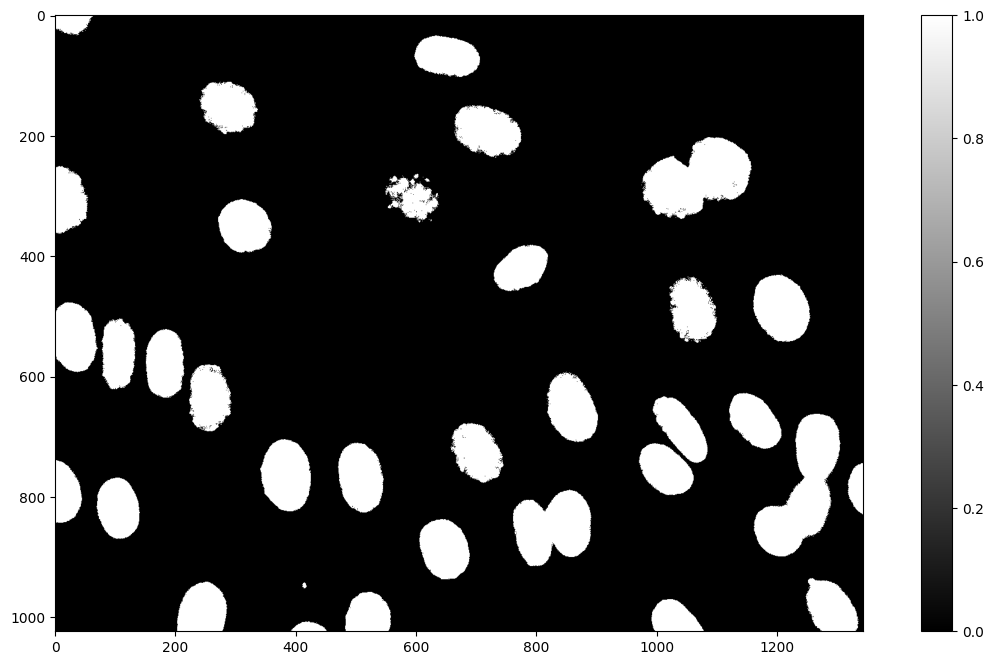

In [10]:
image_seg = img8 >= best_T

plt.figure(figsize=(15, 8))
plt.imshow(image_seg, cmap='gray')
plt.colorbar()

**[Task 1.6.]()** Compute the Dice coefficient:

In [11]:
gt = plt.imread('data/NIH3T3/gt/0.png') > 0

dice = 2 * (image_seg * gt).sum() / (image_seg.sum() + gt.sum())
print('Dice-Koeffizient:', dice)


Dice-Koeffizient: 0.8943783223933183
